# ============================================================
# 04_OULAD_Recommandation_Causale.ipynb
# DropGuard — Système de Recommandation Causale
# KMeans + Analyse Survivants + Groq LLM
# IRD / UGB Saint-Louis — 2026
# ============================================================

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.3/142.3 kB 4.9 MB/s eta 0:00:00


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.cluster     import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics     import silhouette_score
from sklearn.decomposition import PCA
from google.colab        import userdata
from groq                import Groq

print("✅ Imports OK")

✅ Imports OK


In [5]:
BASE_PATH      = '/content/drive/MyDrive/MOOC_Recommandation_Adaptative'
PROCESSED_PATH = f"{BASE_PATH}/data/raw/OULAD/processed"
MODELS_DIR     = f"{BASE_PATH}/results/models"
METRICS_DIR    = f"{BASE_PATH}/results/metrics"
PLOTS_DIR      = f"{BASE_PATH}/results/plots"
RECOMM_DIR     = f"{BASE_PATH}/results/recommandation"

os.makedirs(RECOMM_DIR, exist_ok=True)

print("✅ Chemins configurés")

✅ Chemins configurés


In [6]:
# Dataset J28 (référence pour clustering)
df_j28 = pd.read_csv(
    f"{PROCESSED_PATH}/oulad_enriched_cutoff_28.csv"
)

# Scores dropout du modèle final
df_scores = pd.read_csv(
    f"{PROCESSED_PATH}/dropout_scores_final.csv"
)

# Garder seulement J28 pour les scores
df_scores_j28 = df_scores[df_scores['cutoff_day'] == 28].copy()

# Fusionner
df = pd.merge(
    df_j28,
    df_scores_j28[['id_student','code_module',
                   'code_presentation','dropout_score']],
    on=['id_student','code_module','code_presentation'],
    how='left'
)

print(f"Dataset J28     : {df.shape}")
print(f"Taux abandon    : {df['is_withdrawn'].mean()*100:.1f}%")
print(f"Score moyen     : {df['dropout_score'].mean():.3f}")
print(f"Étudiants       : {df['id_student'].nunique():,}")
print("✅ Données chargées")

Dataset J28     : (32593, 65)
Taux abandon    : 31.2%
Score moyen     : 0.428
Étudiants       : 28,785
✅ Données chargées


In [7]:
# Features comportementales pour clustering
FEATURES_CLUSTER = [
    # Cumulatives
    'total_clicks', 'total_days_active',
    'avg_clicks_per_day', 'last_activity_day',
    'total_span_days', 'avg_score',
    'num_submitted_assessments',
    # Récentes
    'clicks_recent', 'days_active_recent',
    # Dérivées
    'tendance_activite', 'jours_inactivite',
    # Activités VLE disponibles
]

# Ajouter activités VLE disponibles
ACTIVITES_VLE = [
    'forumng','quiz','oucontent','resource',
    'ouwiki','ouelluminate','homepage',
    'subpage','url','glossary'
]
activites_dispo = [a for a in ACTIVITES_VLE if a in df.columns]
FEATURES_CLUSTER += activites_dispo

print(f"Features clustering : {len(FEATURES_CLUSTER)}")
print(f"Activités VLE       : {activites_dispo}")

# Normalisation
df_cluster = df[FEATURES_CLUSTER].fillna(0)
scaler     = StandardScaler()
X_scaled   = scaler.fit_transform(df_cluster)

print(f"X scaled shape : {X_scaled.shape}")
print("✅ Features normalisées")

Features clustering : 21
Activités VLE       : ['forumng', 'quiz', 'oucontent', 'resource', 'ouwiki', 'ouelluminate', 'homepage', 'subpage', 'url', 'glossary']
X scaled shape : (32593, 21)
✅ Features normalisées


Recherche K optimal...
  K=2 | Inertie=511662 | Silhouette=0.3118
  K=3 | Inertie=406905 | Silhouette=0.3377
  K=4 | Inertie=367846 | Silhouette=0.2950
  K=5 | Inertie=347881 | Silhouette=0.2359
  K=6 | Inertie=330594 | Silhouette=0.2416
  K=7 | Inertie=315589 | Silhouette=0.2351
  K=8 | Inertie=302450 | Silhouette=0.2369


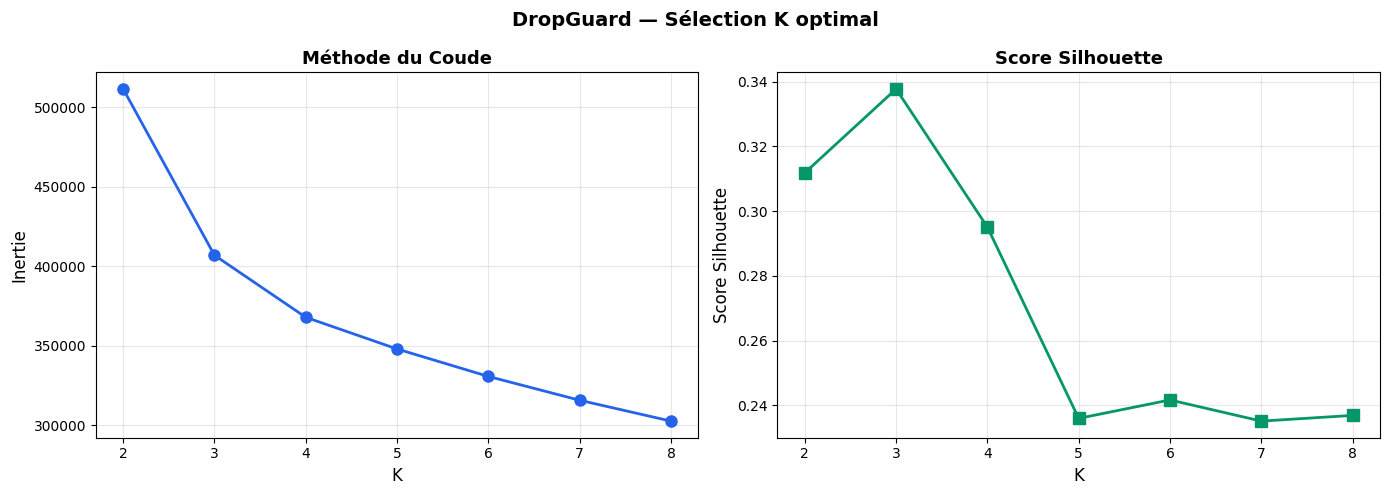

✅ Analyse K terminée


In [8]:
print("Recherche K optimal...")

inertias    = []
silhouettes = []
K_range     = range(2, 9)

for k in K_range:
    km  = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_scaled, km.labels_,
                           sample_size=5000, random_state=42)
    silhouettes.append(sil)
    print(f"  K={k} | Inertie={km.inertia_:.0f} | Silhouette={sil:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, marker='o',
             linewidth=2, color='#2563EB', markersize=8)
axes[0].set_xlabel('K', fontsize=12)
axes[0].set_ylabel('Inertie', fontsize=12)
axes[0].set_title('Méthode du Coude', fontsize=13, fontweight='bold')
axes[0].grid(alpha=0.3)

axes[1].plot(K_range, silhouettes, marker='s',
             linewidth=2, color='#059669', markersize=8)
axes[1].set_xlabel('K', fontsize=12)
axes[1].set_ylabel('Score Silhouette', fontsize=12)
axes[1].set_title('Score Silhouette', fontsize=13, fontweight='bold')
axes[1].grid(alpha=0.3)

plt.suptitle('DropGuard — Sélection K optimal',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/kmeans_selection_k.png",
            dpi=300, bbox_inches='tight')
plt.show()
print("✅ Analyse K terminée")

Distribution des clusters :
Cluster    N          Abandon      Score moy
---------------------------------------------
  1 — À Risque Critique      6,988.0   69.1%      0.787
  2 — Bien Engagés           16,143.0   23.6%      0.369
  0 — Engagés Modérés        8,042.0   16.9%      0.275
  3 — Hyper Engagés          1,420.0   10.7%      0.211


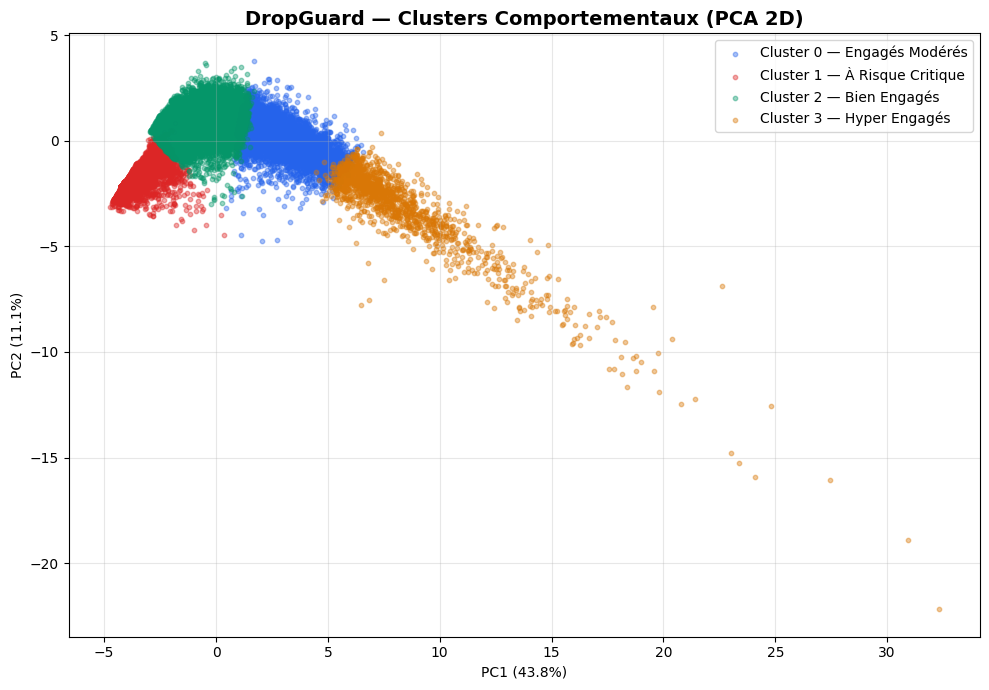

✅ KMeans sauvegardé


In [9]:
K_OPTIMAL = 4

kmeans = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
kmeans.fit(X_scaled)
df['cluster'] = kmeans.labels_

CLUSTER_NAMES = {
    0: "Engagés Modérés",
    1: "À Risque Critique",
    2: "Bien Engagés",
    3: "Hyper Engagés"
}

# Renommer selon taux abandon
cluster_stats = df.groupby('cluster').agg(
    n             = ('id_student','count'),
    taux_abandon  = ('is_withdrawn','mean'),
    score_moyen   = ('dropout_score','mean')
).reset_index().sort_values('taux_abandon', ascending=False)

print("Distribution des clusters :")
print(f"{'Cluster':<10} {'N':<10} {'Abandon':<12} {'Score moy'}")
print("-"*45)
for _, row in cluster_stats.iterrows():
    k    = int(row['cluster'])
    name = CLUSTER_NAMES.get(k, f"Cluster {k}")
    print(f"  {k} — {name:<22} "
          f"{row['n']:>6,}   "
          f"{row['taux_abandon']*100:.1f}%      "
          f"{row['score_moyen']:.3f}")

# Visualisation PCA
pca   = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

colors = ['#2563EB','#DC2626','#059669','#D97706']

plt.figure(figsize=(10, 7))
for k in range(K_OPTIMAL):
    mask = df['cluster'] == k
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=colors[k],
                label=f"Cluster {k} — {CLUSTER_NAMES[k]}",
                alpha=0.4, s=10)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('DropGuard — Clusters Comportementaux (PCA 2D)',
          fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/kmeans_clusters_pca.png",
            dpi=300, bbox_inches='tight')
plt.show()

joblib.dump(kmeans, f"{MODELS_DIR}/kmeans_model.joblib")
joblib.dump(scaler, f"{MODELS_DIR}/scaler_kmeans.joblib")
print("✅ KMeans sauvegardé")

In [10]:
print("="*60)
print("  ANALYSE DES SURVIVANTS PAR CLUSTER")
print("="*60)

ACTIVITES = [a for a in ACTIVITES_VLE if a in df.columns]
survivor_records = []

for k in range(K_OPTIMAL):
    df_k        = df[df['cluster'] == k]
    survivants  = df_k[df_k['is_withdrawn'] == 0]
    abandonneurs = df_k[df_k['is_withdrawn'] == 1]

    print(f"\nCluster {k} — {CLUSTER_NAMES[k]}")
    print(f"  Total : {len(df_k):,} | "
          f"Survivants : {len(survivants):,} | "
          f"Abandons : {len(abandonneurs):,}")
    print(f"  {'Activité':<15} {'Survivants':>12} "
          f"{'Abandonneurs':>14} {'Différence':>12}")
    print(f"  {'-'*55}")

    for act in ACTIVITES:
        moy_s = survivants[act].mean()
        moy_a = abandonneurs[act].mean()
        diff  = moy_s - moy_a
        marker = "⬆️" if diff > 0 else "⬇️"
        print(f"  {act:<15} {moy_s:>12.2f} "
              f"{moy_a:>14.2f} {diff:>+12.2f} {marker}")

        survivor_records.append({
            'cluster'          : k,
            'cluster_name'     : CLUSTER_NAMES[k],
            'activite'         : act,
            'moy_survivants'   : moy_s,
            'moy_abandonneurs' : moy_a,
            'difference'       : diff,
            'impact'           : abs(diff)
        })

df_survivor = pd.DataFrame(survivor_records)
df_survivor.to_csv(f"{RECOMM_DIR}/survivor_analysis.csv",
                   index=False)
print("\n✅ Analyse survivants sauvegardée")

  ANALYSE DES SURVIVANTS PAR CLUSTER

Cluster 0 — Engagés Modérés
  Total : 8,042 | Survivants : 6,682 | Abandons : 1,360
  Activité          Survivants   Abandonneurs   Différence
  -------------------------------------------------------
  forumng               158.62         138.11       +20.51 ⬆️
  quiz                   86.65          87.98        -1.33 ⬇️
  oucontent             135.14         121.06       +14.08 ⬆️
  resource               20.62          22.00        -1.38 ⬇️
  ouwiki                 11.49          11.26        +0.23 ⬆️
  ouelluminate            0.68           0.78        -0.10 ⬇️
  homepage              115.38         111.64        +3.74 ⬆️
  subpage                66.50          69.21        -2.71 ⬇️
  url                    12.97          12.68        +0.29 ⬆️
  glossary                1.54           1.03        +0.51 ⬆️

Cluster 1 — À Risque Critique
  Total : 6,988 | Survivants : 2,156 | Abandons : 4,832
  Activité          Survivants   Abandonneurs   Différ

In [11]:
# Top activités par cluster (depuis analyse survivants)
TOP_ACTIVITES_CLUSTER = {}
for k in range(K_OPTIMAL):
    top = (df_survivor[df_survivor['cluster'] == k]
           .sort_values('difference', ascending=False)
           .head(3)['activite']
           .tolist())
    TOP_ACTIVITES_CLUSTER[k] = top
    print(f"Cluster {k} — {CLUSTER_NAMES[k]} : {top}")

# Causes SHAP → conseils pédagogiques
CAUSES = {
    'inactivite': {
        'description' : 'Inactivité comportementale',
        'conseil'     : 'Reprends contact avec le cours — commence par des contenus courts',
        'message_type': 'engagement',
        'activites'   : ['homepage','oucontent','forumng']
    },
    'difficulte_academique': {
        'description' : 'Difficulté académique',
        'conseil'     : 'Consulte les ressources et demande de l aide sur le forum',
        'message_type': 'remediation',
        'activites'   : ['oucontent','resource','forumng']
    },
    'surcharge': {
        'description' : 'Surcharge de crédits',
        'conseil'     : 'Priorise les contenus essentiels et gère ton temps',
        'message_type': 'organisation',
        'activites'   : ['oucontent','homepage','resource']
    },
    'desengagement_module': {
        'description' : 'Désengagement du module',
        'conseil'     : 'Rejoins la communauté et explore des contenus variés',
        'message_type': 'motivation',
        'activites'   : ['forumng','oucontent','ouwiki']
    }
}

# Construction table 16 combinaisons
records = []
for k in range(K_OPTIMAL):
    for cause, info in CAUSES.items():
        # Fusionner activités cause + activités cluster
        merged = []
        for a in info['activites']:
            if a not in merged:
                merged.append(a)
        for a in TOP_ACTIVITES_CLUSTER[k]:
            if a not in merged:
                merged.append(a)
        final_acts = merged[:3]

        records.append({
            'cluster'      : k,
            'cluster_name' : CLUSTER_NAMES[k],
            'cause_shap'   : cause,
            'cause_desc'   : info['description'],
            'activite_1'   : final_acts[0],
            'activite_2'   : final_acts[1] if len(final_acts)>1 else '',
            'activite_3'   : final_acts[2] if len(final_acts)>2 else '',
            'message_type' : info['message_type'],
            'conseil'      : info['conseil'],
        })

df_recomm = pd.DataFrame(records)
df_recomm.to_csv(f"{RECOMM_DIR}/recommendation_table.csv",
                 index=False)

print(f"\nTable de recommandation : {df_recomm.shape}")
print(df_recomm[['cluster_name','cause_shap',
                  'activite_1','activite_2',
                  'activite_3']].to_string(index=False))
print("\n✅ Table de recommandation sauvegardée")

Cluster 0 — Engagés Modérés : ['forumng', 'oucontent', 'homepage']
Cluster 1 — À Risque Critique : ['homepage', 'forumng', 'resource']
Cluster 2 — Bien Engagés : ['forumng', 'oucontent', 'homepage']
Cluster 3 — Hyper Engagés : ['forumng', 'oucontent', 'quiz']

Table de recommandation : (16, 9)
     cluster_name            cause_shap activite_1 activite_2 activite_3
  Engagés Modérés            inactivite   homepage  oucontent    forumng
  Engagés Modérés difficulte_academique  oucontent   resource    forumng
  Engagés Modérés             surcharge  oucontent   homepage   resource
  Engagés Modérés  desengagement_module    forumng  oucontent     ouwiki
À Risque Critique            inactivite   homepage  oucontent    forumng
À Risque Critique difficulte_academique  oucontent   resource    forumng
À Risque Critique             surcharge  oucontent   homepage   resource
À Risque Critique  desengagement_module    forumng  oucontent     ouwiki
     Bien Engagés            inactivite   homepa

In [14]:
# Initialisation Groq
client_groq = Groq(api_key=userdata.get('GROQ_API_KEY'))

NOMS_ACTIVITES = {
    'forumng'     : 'Forum de discussion',
    'quiz'        : 'Quiz de révision',
    'oucontent'   : 'Contenus du cours',
    'resource'    : 'Ressources complémentaires',
    'ouwiki'      : 'Wiki collaboratif',
    'ouelluminate': 'Sessions en ligne',
    'homepage'    : "Page d'accueil du cours",
    'subpage'     : 'Sous-pages du cours',
    'url'         : 'Liens externes',
    'glossary'    : 'Glossaire',
}

def generer_message(prenom, cluster_name,
                    cause_desc, activites, conseil):
    prompt = f"""Tu es un tuteur bienveillant dans une plateforme MOOC.
Écris un message court (3-4 phrases) et encourageant pour {prenom}.
Profil : {cluster_name} | Cause : {cause_desc}
Conseil : {conseil}
Activités recommandées : {', '.join(activites)}

Contraintes : commence par "Bonjour {prenom},",
maximum 4 phrases, ton chaleureux,
NE PAS mentionner de score ou risque."""

    try:
        response = client_groq.chat.completions.create(
            model       = "llama-3.1-8b-instant",
            messages    = [{"role":"user","content":prompt}],
            max_tokens  = 200,
            temperature = 0.7
        )
        return response.choices[0].message.content.strip()
    except Exception:
        return f"Bonjour {prenom}, {conseil} 💪"


def recommander(prenom, cluster_id, cause_shap):
    """Fonction principale de recommandation."""
    row = df_recomm[
        (df_recomm['cluster']    == cluster_id) &
        (df_recomm['cause_shap'] == cause_shap)
    ].iloc[0]

    activites = [
        NOMS_ACTIVITES.get(row['activite_1'], row['activite_1']),
        NOMS_ACTIVITES.get(row['activite_2'], row['activite_2']),
        NOMS_ACTIVITES.get(row['activite_3'], row['activite_3']),
    ]
    activites = [a for a in activites if a]

    message = generer_message(
        prenom, row['cluster_name'],
        row['cause_desc'], activites, row['conseil']
    )

    return {
        'cluster_id'   : cluster_id,
        'cluster_name' : row['cluster_name'],
        'activites'    : activites,
        'message'      : message,
        'conseil'      : row['conseil'],
    }

print("✅ Fonctions Groq définies")

✅ Fonctions Groq définies


In [15]:
print("="*60)
print("  TEST END-TO-END — 5 ÉTUDIANTS")
print("="*60)

import shap as shap_lib
model_final = joblib.load(
    f"{MODELS_DIR}/xgboost_dropguard_final.joblib"
)

with open(f"{MODELS_DIR}/feature_names_final.json") as f:
    FEATURE_NAMES = json.load(f)

explainer_shap = shap_lib.TreeExplainer(model_final)

CAUSE_GROUPS = {
    'inactivite'           : ['jours_inactivite',
                              'last_activity_day',
                              'days_active_recent',
                              'tendance_activite',
                              'total_days_active'],
    'difficulte_academique': ['avg_score','TMA',
                              'CMA','num_submitted_assessments'],
    'surcharge'            : ['studied_credits'],
    'desengagement_module' : ['forumng','quiz','oucontent',
                              'resource','ouwiki',
                              'forumng_recent','quiz_recent']
}

def identifier_cause(shap_dict):
    scores = {}
    for cause, feats in CAUSE_GROUPS.items():
        scores[cause] = sum(
            shap_dict.get(f, 0) for f in feats
            if shap_dict.get(f, 0) > 0
        )
    return max(scores, key=scores.get) \
           if sum(scores.values()) > 0 else 'inactivite'

PRENOMS = ['Amadou','Fatou','Moussa','Aissatou','Ibrahima']
df_test = df[df['dropout_score'] > 0.5].sample(5, random_state=42)
resultats = []

for i, (_, etudiant) in enumerate(df_test.iterrows()):
    prenom     = PRENOMS[i]
    cluster_id = int(etudiant['cluster'])
    score      = etudiant['dropout_score']

    # SHAP
    X_etud = pd.DataFrame([etudiant.to_dict()])
    for feat in FEATURE_NAMES:
        if feat not in X_etud.columns:
            X_etud[feat] = 0
    X_etud     = X_etud[FEATURE_NAMES].fillna(0)
    shap_vals  = explainer_shap.shap_values(X_etud)[0]
    shap_dict  = dict(zip(FEATURE_NAMES, shap_vals))
    cause      = identifier_cause(shap_dict)

    # Recommandation
    rec = recommander(prenom, cluster_id, cause)

    print(f"\n{'='*55}")
    print(f"  {prenom} | Cluster : {CLUSTER_NAMES[cluster_id]}")
    print(f"  Score : {score:.3f} | Cause : {cause}")
    print(f"  Activités : {rec['activites']}")
    print(f"\n  MESSAGE :\n  {rec['message']}")

    resultats.append({
        'prenom'    : prenom,
        'cluster'   : cluster_id,
        'cause'     : cause,
        'score'     : score,
        'activites' : str(rec['activites']),
        'message'   : rec['message']
    })

pd.DataFrame(resultats).to_csv(
    f"{RECOMM_DIR}/messages_test.csv", index=False
)
print("\n✅ Test end-to-end terminé")

  TEST END-TO-END — 5 ÉTUDIANTS

  Amadou | Cluster : Bien Engagés
  Score : 0.658 | Cause : difficulte_academique
  Activités : ['Contenus du cours', 'Ressources complémentaires', 'Forum de discussion']

  MESSAGE :
  Bonjour Amadou,

Je suis ravi de voir que tu es engagé dans ce cours ! Si tu te sens un peu perdu ou que les concepts académiques sont difficiles à comprendre, n'hésite pas à consulter les ressources complémentaires et à demander de l'aide sur le forum. Tu es en bonne compagnie et nous sommes là pour t'aider à progresser. Continue à travailler fort et à poser tes questions !

  Fatou | Cluster : À Risque Critique
  Score : 0.895 | Cause : inactivite
  Activités : ["Page d'accueil du cours", 'Contenus du cours', 'Forum de discussion']

  MESSAGE :
  Bonjour Fatou,

Je suis ravi de te revoir ! Je sais que tu es capable de relever les défis, et je suis là pour t'aider. Pour commencer, je t'encourage à visiter la page d'accueil du cours, en explore les contenus et à particip

In [16]:
print("="*60)
print("  SAUVEGARDE FINALE NB04")
print("="*60)

# Templates messages
templates = {}
for cause, info in CAUSES.items():
    templates[cause] = {
        'description' : info['description'],
        'conseil'     : info['conseil'],
        'message_type': info['message_type'],
        'activites'   : info['activites']
    }

with open(f"{RECOMM_DIR}/message_templates.json",
          'w', encoding='utf-8') as f:
    json.dump(templates, f, ensure_ascii=False, indent=2)

# Features clustering
with open(f"{RECOMM_DIR}/features_cluster.json", 'w') as f:
    json.dump(FEATURES_CLUSTER, f, indent=2)

print("Fichiers sauvegardés :")
print("  ✅ kmeans_model.joblib")
print("  ✅ scaler_kmeans.joblib")
print("  ✅ recommendation_table.csv")
print("  ✅ survivor_analysis.csv")
print("  ✅ message_templates.json")
print("  ✅ features_cluster.json")
print("  ✅ messages_test.csv")
print(f"\n{'='*60}")
print("  NB04 TERMINÉ")
print(f"{'='*60}")
print(f"  Clusters    : {K_OPTIMAL} profils comportementaux")
print(f"  Survivants  : activités différenciatrices identifiées")
print(f"  Table       : {len(df_recomm)} combinaisons cluster × cause")
print(f"  LLM         : Groq llama3-8b — messages personnalisés")
print(f"  Prêt pour intégration plugin Moodle ✅")

  SAUVEGARDE FINALE NB04
Fichiers sauvegardés :
  ✅ kmeans_model.joblib
  ✅ scaler_kmeans.joblib
  ✅ recommendation_table.csv
  ✅ survivor_analysis.csv
  ✅ message_templates.json
  ✅ features_cluster.json
  ✅ messages_test.csv

  NB04 TERMINÉ
  Clusters    : 4 profils comportementaux
  Survivants  : activités différenciatrices identifiées
  Table       : 16 combinaisons cluster × cause
  LLM         : Groq llama3-8b — messages personnalisés
  Prêt pour intégration plugin Moodle ✅
